# 02. 데이터 탐색 및 ESG 등급 연계 분석

이 노트북은 DART 사업보고서의 II, IV, VI 섹션에서 추출한 ESG 관련 passage를 `stock_code × esg_year` 기업-연도 단위로 집계하고, KCGS ESG 등급과의 연관성을 탐색합니다.

핵심 원칙은 `esg_year = fiscal_year + 1`입니다. 예를 들어 2025년 KCGS 등급은 2024 회계연도 사업보고서의 공시 언어와 연결합니다. 이 분석은 인과효과가 아니라 텍스트 feature와 등급 사이의 탐색적 연관성을 확인하는 용도입니다.


In [1]:
from pathlib import Path
import platform
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import font_manager
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score

try:
    from scipy import stats
    SCIPY_AVAILABLE = True
except Exception:
    SCIPY_AVAILABLE = False

warnings.filterwarnings('ignore')

PROJECT_ROOT = Path.cwd().resolve()
if PROJECT_ROOT.name == 'notebooks':
    PROJECT_ROOT = PROJECT_ROOT.parent

DATA_RAW = PROJECT_ROOT / 'data' / 'raw'
DATA_PROCESSED = PROJECT_ROOT / 'data' / 'processed'
PASSAGES_CSV = DATA_PROCESSED / 'dart_passages.csv'
CHECKPOINT_CSV = DATA_PROCESSED / 'dart_collection_checkpoint.csv'
COMPANY_MASTER_CSV = DATA_RAW / 'company_master.csv'
SEED_DICTIONARY_CSV = DATA_RAW / 'seed_dictionary.csv'

pd.set_option('display.max_columns', 120)
pd.set_option('display.max_colwidth', 120)
pd.set_option('display.float_format', lambda x: f'{x:,.4f}')


def set_korean_font():
    candidates_by_os = {
        'Darwin': ['AppleGothic', 'NanumGothic', 'Malgun Gothic'],
        'Windows': ['Malgun Gothic', 'NanumGothic', 'AppleGothic'],
        'Linux': ['NanumGothic', 'Malgun Gothic', 'AppleGothic'],
    }
    candidates = candidates_by_os.get(platform.system(), ['NanumGothic', 'AppleGothic', 'Malgun Gothic'])
    installed = {f.name for f in font_manager.fontManager.ttflist}
    for font_name in candidates:
        if font_name in installed:
            plt.rcParams['font.family'] = font_name
            plt.rcParams['axes.unicode_minus'] = False
            return font_name
    plt.rcParams['axes.unicode_minus'] = False
    return None

FONT_NAME = set_korean_font()
plt.rcParams['figure.figsize'] = (10, 5)
plt.rcParams['axes.grid'] = True
plt.rcParams['grid.alpha'] = 0.25
plt.rcParams['axes.spines.top'] = False
plt.rcParams['axes.spines.right'] = False

print('PROJECT_ROOT:', PROJECT_ROOT)
print('Korean font:', FONT_NAME or 'not found; using matplotlib default')
print('scipy available:', SCIPY_AVAILABLE)


PROJECT_ROOT: /Users/home1/Documents/esg-dart-project
Korean font: AppleGothic
scipy available: True


## 1. 입력 파일 확인 및 로딩

분석은 이미 수집된 local CSV만 사용합니다. OpenDART API를 다시 호출하지 않으며, 실패 행을 텍스트 점수 0으로 채우지 않습니다.


In [2]:
required_files = [PASSAGES_CSV, CHECKPOINT_CSV, COMPANY_MASTER_CSV, SEED_DICTIONARY_CSV]
missing_files = [p for p in required_files if not p.exists()]
assert not missing_files, f'필수 입력 파일이 없습니다: {missing_files}'

passages = pd.read_csv(PASSAGES_CSV)
checkpoint = pd.read_csv(CHECKPOINT_CSV)
company_master = pd.read_csv(COMPANY_MASTER_CSV)
seed_dict = pd.read_csv(SEED_DICTIONARY_CSV)

for df in [passages, checkpoint, company_master]:
    if 'stock_code' in df.columns:
        df['stock_code_str'] = df['stock_code'].astype(int).astype(str).str.zfill(6)

print('passages:', passages.shape)
print('checkpoint:', checkpoint.shape)
print('company_master:', company_master.shape)
print('seed_dictionary:', seed_dict.shape)

display(passages.head(3))
display(company_master.head(3))
display(seed_dict.head(10))


passages: (39322, 13)
checkpoint: (381, 17)
company_master: (381, 14)
seed_dictionary: (30, 6)


,company_name,stock_code,corp_code,esg_year,fiscal_year,rcept_no,rcept_dt,viewer_url,section,passage,dimension,matched_terms,stock_code_str
0,삼성전자,5930,126380,2023,2022,20230307000542,20230307,https://dart.fss.or.kr/dsaf001/main.do?rcpNo=20230307000542,II,당사의 자본관리 목적은 계속기업으로서 주주 및 이해관계자에게 이익을 지속적으로제공할 수 있는 능력을 보호하고 건전한 자본구조를 유지하는 것입니다,G,주주,005930
1,삼성전자,5930,126380,2023,2022,20230307000542,20230307,https://dart.fss.or.kr/dsaf001/main.do?rcpNo=20230307000542,II,"또한, 삼성디스플레이㈜는 TCL Technology Group Corporation (TCL) 및 TCL China Star Optoelectronics Technology Co. Ltd. (CSOT)와 20...",G,주주,005930
2,삼성전자,5930,126380,2023,2022,20230307000542,20230307,https://dart.fss.or.kr/dsaf001/main.do?rcpNo=20230307000542,II,특히 정부의 저탄소 녹색성장 정책에 부응하여 관련 법규에서요구하는 사업장에서 발생하는 온실가스 배출량과 에너지 사용량을 정부에 신고하고지속가능보고서 등을 통하여 이해관계자에게 관련 정보를 투명하게 제공하고 있습니다,E,에너지|온실가스|탄소,005930


,company_name,corp_code,stock_code,industry,fiscal_year,report_code,rcept_no,esg_source,esg_grade,e_grade,s_grade,g_grade,esg_year,stock_code_str
0,삼성전자,NaN,5930,전기전자,2022,11011,NaN,한국ESG기준원,A,A,A+,B+,2023,005930
1,삼성전자,NaN,5930,전기전자,2023,11011,NaN,한국ESG기준원,B+,B+,A,B,2024,005930
2,삼성전자,NaN,5930,전기전자,2024,11011,NaN,한국ESG기준원,A,B+,A+,B+,2025,005930


,dimension,seed_term,pattern,source_basis,source_titles,notes
0,E,탄소,탄소,Bloomberg ESG climate change; Sautner-style climate exposure,Bloomberg ESG framework; Sautner-style climate change exposure; Alam et al. (2025),carbon / climate exposure core seed
1,E,온실가스,온실가스|GHG,Bloomberg ESG climate change; GHG emissions literature,Bloomberg ESG framework; Sautner-style climate change exposure; Alam et al. (2025),greenhouse gas emissions seed
2,E,탄소중립,탄소중립,Bloomberg ESG climate change; net-zero transition literature,Bloomberg ESG framework; Sautner-style climate change exposure; Alam et al. (2025),net-zero transition Korean term
3,E,넷제로,넷제로|net zero|net-zero,Bloomberg ESG climate change; net-zero transition literature,Bloomberg ESG framework; Sautner-style climate change exposure; Alam et al. (2025),net-zero borrowed term
4,E,재생에너지,재생에너지|renewable energy,Bloomberg ESG water/energy management; climate opportunity literature,Bloomberg ESG framework; Sautner-style climate change exposure; Alam et al. (2025),renewable energy seed
5,E,에너지,에너지,Bloomberg ESG water/energy management,Bloomberg ESG framework; Alam et al. (2025),energy management broad seed
6,E,전력,전력|전력사용량,Bloomberg ESG energy management,Bloomberg ESG framework; Alam et al. (2025),power usage operational seed
7,E,폐기물,폐기물,Bloomberg ESG material and waste,Bloomberg ESG framework; Bao et al. (2024),material and waste seed
8,E,재활용,재활용|자원순환,Bloomberg ESG material and waste,Bloomberg ESG framework; Bao et al. (2024),waste recycling / circularity seed
9,E,폐수,폐수|수질|물관리,Bloomberg ESG water management,Bloomberg ESG framework; Bao et al. (2024),water / wastewater management seed


In [3]:
print('passages dtypes')
display(passages.dtypes.to_frame('dtype'))
print('passages missing values')
display(passages.isna().sum().to_frame('missing'))
print('company_master missing values')
display(company_master.isna().sum().to_frame('missing'))


passages dtypes


,dtype
company_name,str
stock_code,int64
corp_code,int64
esg_year,int64
fiscal_year,int64
rcept_no,int64
rcept_dt,int64
viewer_url,str
section,str
passage,str


passages missing values


,missing
company_name,0
stock_code,0
corp_code,0
esg_year,0
fiscal_year,0
rcept_no,0
rcept_dt,0
viewer_url,0
section,0
passage,0


company_master missing values


,missing
company_name,0
corp_code,381
stock_code,0
industry,297
fiscal_year,0
report_code,0
rcept_no,381
esg_source,0
esg_grade,0
e_grade,0


## 2. 데이터 lineage와 수집 상태 점검

과제 기준 표본은 `company_master.csv`의 381개 기업-연도입니다. 분석 corpus는 이 중 DART 보고서와 ESG passage 추출에 성공한 기업-연도만 포함합니다.


In [4]:
key = ['stock_code', 'esg_year']
master_keys = company_master[key + ['company_name', 'fiscal_year', 'esg_grade', 'e_grade', 's_grade', 'g_grade', 'industry', 'stock_code_str']].copy()
checkpoint_small = checkpoint[key + ['corp_code', 'rcept_no', 'rcept_dt', 'viewer_url', 'report_nm', 'status', 'failure_stage', 'failure_reason', 'section_II_chars', 'section_IV_chars', 'section_VI_chars', 'passage_count', 'stock_code_str']].copy()
lineage = master_keys.merge(
    checkpoint_small.drop(columns=['stock_code_str']),
    on=key,
    how='left',
    validate='one_to_one',
)
lineage['timing_ok'] = lineage['esg_year'].eq(lineage['fiscal_year'] + 1)
lineage['total_section_chars'] = lineage[['section_II_chars', 'section_IV_chars', 'section_VI_chars']].sum(axis=1)

print('company_master firm-years:', len(company_master))
print('matched checkpoint firm-years:', lineage['status'].notna().sum())
print('timing ok:', int(lineage['timing_ok'].sum()), '/', len(lineage))
display(lineage['status'].value_counts(dropna=False).rename_axis('status').to_frame('firm_years'))
display(lineage.loc[lineage['status'].eq('FAIL'), ['company_name', 'stock_code_str', 'esg_year', 'fiscal_year', 'status', 'failure_stage', 'failure_reason']])


company_master firm-years: 381
matched checkpoint firm-years: 381
timing ok: 381 / 381


,firm_years
status,
OK,360
SKIP_EXISTING,16
FAIL,5


,company_name,stock_code_str,esg_year,fiscal_year,status,failure_stage,failure_reason
222,신영증권,001720,2023,2022,FAIL,list.json,2022 회계연도 사업보고서를 찾지 못했습니다. 조회 예시: ['사업보고서 (2023.03)']
223,신영증권,001720,2024,2023,FAIL,list.json,2023 회계연도 사업보고서를 찾지 못했습니다. 조회 예시: ['사업보고서 (2024.03)']
224,신영증권,001720,2025,2024,FAIL,list.json,"2024 회계연도 사업보고서를 찾지 못했습니다. 조회 예시: ['[기재정정]사업보고서 (2025.03)', '사업보고서 (2025.03)']"
351,만호제강,001080,2023,2022,FAIL,list.json,2022 회계연도 사업보고서를 찾지 못했습니다. 조회 예시: ['사업보고서 (2023.06)']
352,만호제강,001080,2024,2023,FAIL,list.json,2023 회계연도 사업보고서를 찾지 못했습니다. 조회 예시: ['사업보고서 (2024.06)']


In [5]:
passage_key_counts = passages.groupby(key).size().rename('passage_count_from_passages').reset_index()
lineage_check = lineage.merge(passage_key_counts, on=key, how='left')
lineage_check['passage_count_from_passages'] = lineage_check['passage_count_from_passages'].fillna(0).astype(int)
lineage_check['passage_count_diff'] = lineage_check['passage_count_from_passages'] - lineage_check['passage_count'].fillna(0).astype(int)

success_keys = passage_key_counts[key].drop_duplicates()
print('passage가 있는 firm-years:', len(success_keys))
print('등급 매칭 누락:', success_keys.merge(company_master[key + ['esg_grade']], on=key, how='left')['esg_grade'].isna().sum())
print('checkpoint passage_count와 재집계 불일치:', int(lineage_check['passage_count_diff'].ne(0).sum()))
display(lineage_check.loc[lineage_check['passage_count_diff'].ne(0), ['company_name', 'stock_code_str', 'esg_year', 'status', 'passage_count', 'passage_count_from_passages', 'passage_count_diff']].head(20))


passage가 있는 firm-years: 376
등급 매칭 누락: 0
checkpoint passage_count와 재집계 불일치: 0


,company_name,stock_code_str,esg_year,status,passage_count,passage_count_from_passages,passage_count_diff


## 3. Passage 빈도와 분포 EDA

먼저 ESG passage 자체의 연도, 섹션, dimension 분포를 확인합니다.


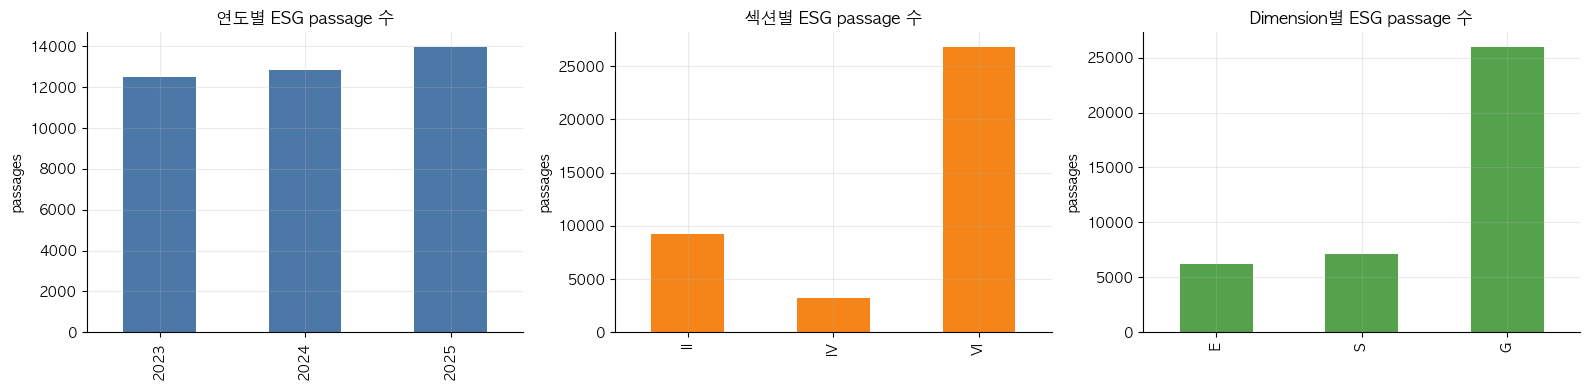

[year]


,passages
esg_year,
2023,12497
2024,12844
2025,13981


[section]


,passages
section,
II,9221
IV,3266
VI,26835


[dimension]


,passages
dimension,
E,6218
S,7114
G,25990


In [6]:
passages_eda = passages.copy()
passages_eda['passage_length'] = passages_eda['passage'].astype(str).str.len()
passages_eda['matched_terms_list'] = passages_eda['matched_terms'].fillna('').astype(str).str.split('|')

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
passages_eda['esg_year'].value_counts().sort_index().plot(kind='bar', ax=axes[0], color='#4C78A8', title='연도별 ESG passage 수')
passages_eda['section'].value_counts().sort_index().plot(kind='bar', ax=axes[1], color='#F58518', title='섹션별 ESG passage 수')
passages_eda['dimension'].value_counts().reindex(['E', 'S', 'G']).plot(kind='bar', ax=axes[2], color='#54A24B', title='Dimension별 ESG passage 수')
for ax in axes:
    ax.set_xlabel('')
    ax.set_ylabel('passages')
plt.tight_layout()
plt.show()

summary_tables = {
    'year': passages_eda['esg_year'].value_counts().sort_index(),
    'section': passages_eda['section'].value_counts().sort_index(),
    'dimension': passages_eda['dimension'].value_counts().reindex(['E', 'S', 'G']),
}
for name, table in summary_tables.items():
    print(f'[{name}]')
    display(table.to_frame('passages'))


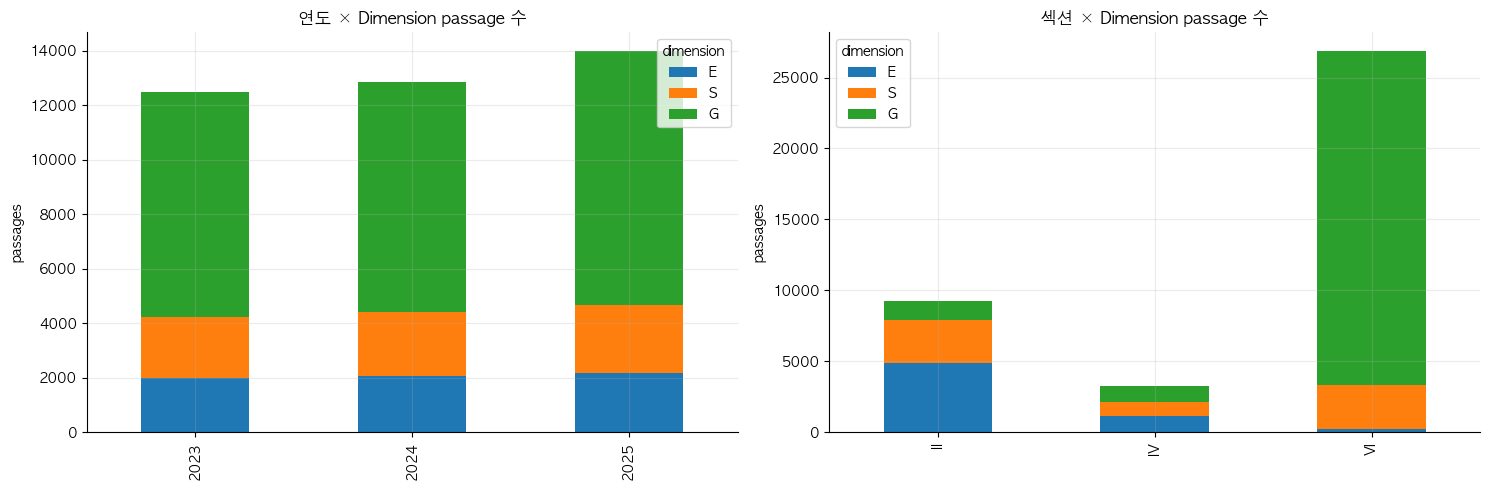

dimension,E,S,G
esg_year,,,
2023,1977,2264,8256
2024,2059,2367,8418
2025,2182,2483,9316


dimension,E,S,G
section,,,
II,4861,3018,1342
IV,1142,982,1142
VI,215,3114,23506


In [7]:
dim_by_year = pd.crosstab(passages_eda['esg_year'], passages_eda['dimension']).reindex(columns=['E', 'S', 'G'])
section_by_dim = pd.crosstab(passages_eda['section'], passages_eda['dimension']).reindex(columns=['E', 'S', 'G'])

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
dim_by_year.plot(kind='bar', stacked=True, ax=axes[0], title='연도 × Dimension passage 수')
section_by_dim.plot(kind='bar', stacked=True, ax=axes[1], title='섹션 × Dimension passage 수')
for ax in axes:
    ax.set_xlabel('')
    ax.set_ylabel('passages')
plt.tight_layout()
plt.show()

display(dim_by_year)
display(section_by_dim)


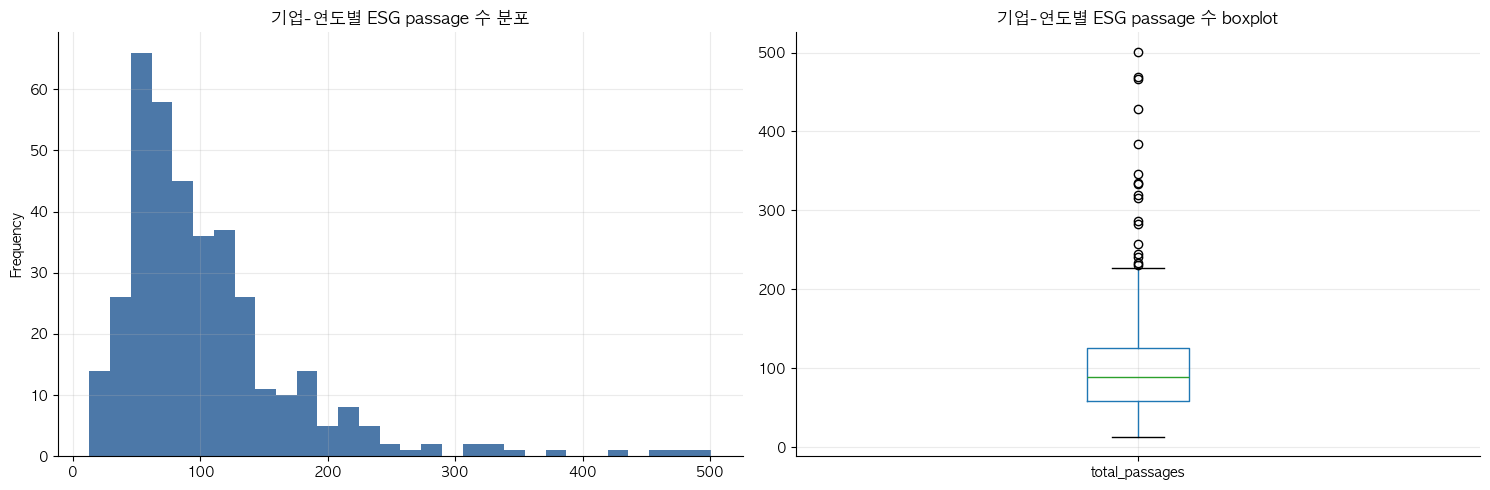

,stock_code,esg_year,company_name,stock_code_str,total_passages
274,5490,2023,POSCO홀딩스,005490,501
276,5490,2025,POSCO홀딩스,005490,469
275,5490,2024,POSCO홀딩스,005490,467
360,96770,2025,SK이노베이션,096770,429
116,880,2025,한화,000880,384
114,880,2023,한화,000880,346
115,880,2024,한화,000880,335
366,105560,2025,KB금융,105560,334
364,105560,2023,KB금융지주,105560,320
365,105560,2024,KB금융,105560,316


In [8]:
firm_year_counts = passages_eda.groupby(key + ['company_name', 'stock_code_str']).size().rename('total_passages').reset_index()

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
firm_year_counts['total_passages'].plot(kind='hist', bins=30, ax=axes[0], color='#4C78A8', title='기업-연도별 ESG passage 수 분포')
firm_year_counts.boxplot(column='total_passages', ax=axes[1])
axes[1].set_title('기업-연도별 ESG passage 수 boxplot')
plt.tight_layout()
plt.show()

display(firm_year_counts.sort_values('total_passages', ascending=False).head(15))


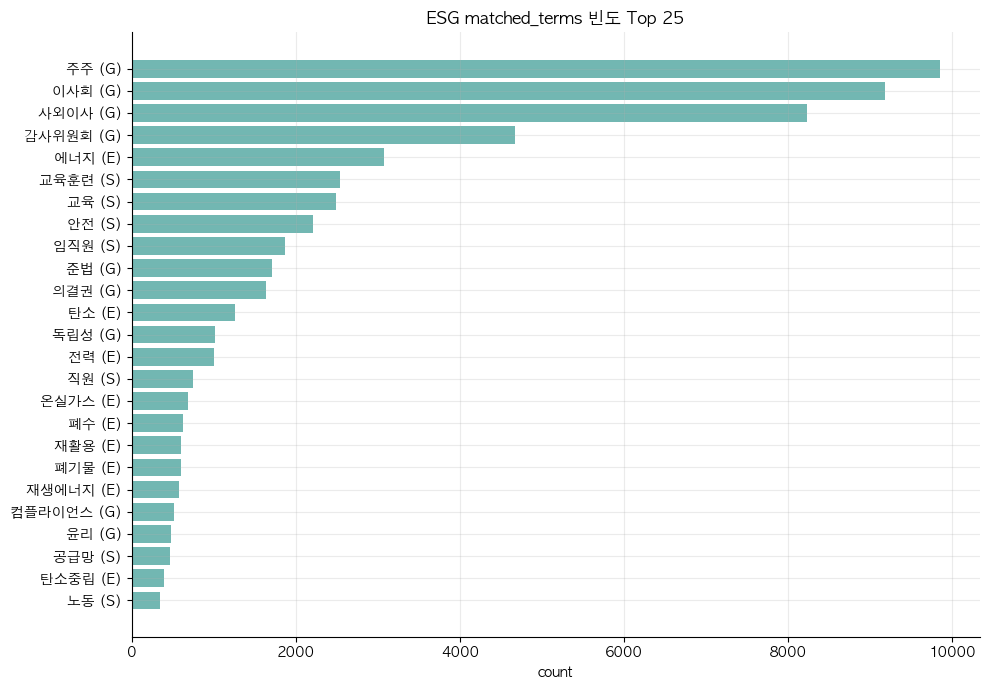

,dimension,term,count
30,G,주주,9848
29,G,이사회,9180
26,G,사외이사,8234
22,G,감사위원회,4673
8,E,에너지,3081
40,S,교육훈련,2544
39,S,교육,2485
45,S,안전,2210
47,S,임직원,1868
31,G,준법,1704


In [9]:
terms_long = passages_eda.explode('matched_terms_list').rename(columns={'matched_terms_list': 'term'})
terms_long['term'] = terms_long['term'].astype(str).str.strip()
terms_long = terms_long[terms_long['term'].ne('')]
term_counts = terms_long.groupby(['dimension', 'term']).size().rename('count').reset_index().sort_values('count', ascending=False)

top_terms = term_counts.head(25).sort_values('count')
plt.figure(figsize=(10, 7))
plt.barh(top_terms['term'] + ' (' + top_terms['dimension'] + ')', top_terms['count'], color='#72B7B2')
plt.title('ESG matched_terms 빈도 Top 25')
plt.xlabel('count')
plt.tight_layout()
plt.show()

display(term_counts.groupby('dimension').head(10))


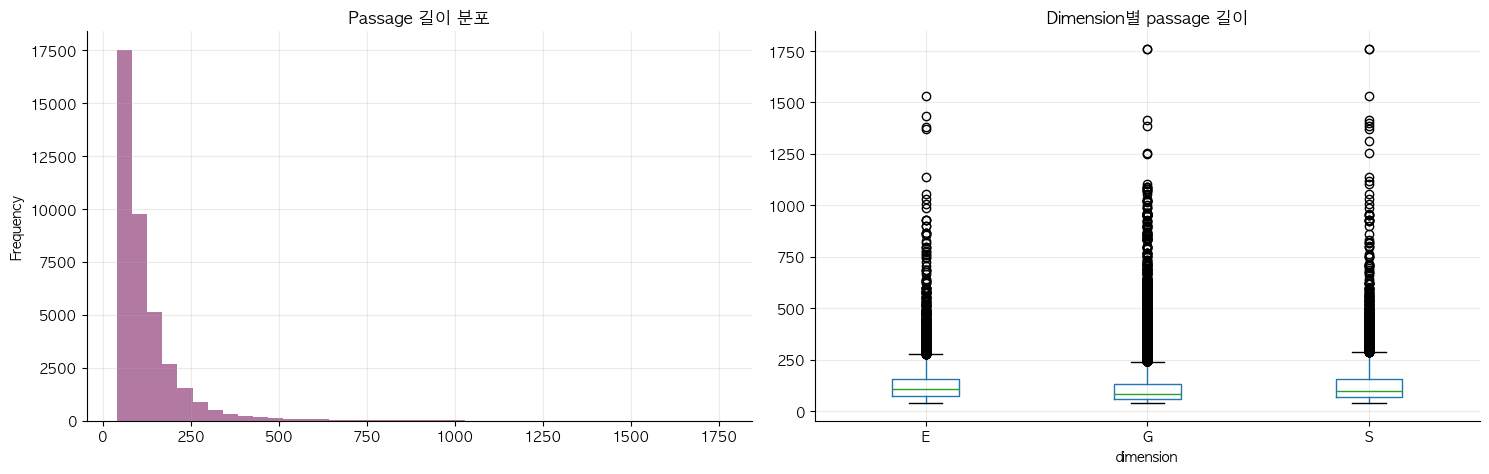

,passage_length
count,"39,322.0000"
mean,120.5636
std,102.3937
min,40.0000
25%,62.0000
50%,90.0000
75%,141.0000
max,"1,759.0000"


In [10]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
passages_eda['passage_length'].plot(kind='hist', bins=40, ax=axes[0], color='#B279A2', title='Passage 길이 분포')
passages_eda.boxplot(column='passage_length', by='dimension', ax=axes[1])
axes[1].set_title('Dimension별 passage 길이')
axes[1].set_xlabel('dimension')
plt.suptitle('')
plt.tight_layout()
plt.show()

display(passages_eda['passage_length'].describe().to_frame('passage_length'))


## 4. 기업-연도 분석 패널 생성

passage를 기업-연도 단위로 집계하고 KCGS 등급을 숫자로 변환합니다. 등급은 서열변수이므로 Spearman 순위상관을 우선 해석합니다.


In [11]:
GRADE_MAP = {'D': 0, 'C': 1, 'B': 2, 'B+': 3, 'A': 4, 'A+': 5, 'S': 6}
GRADE_ORDER = ['D', 'C', 'B', 'B+', 'A', 'A+', 'S']

dim_counts = (
    passages_eda.pivot_table(index=key, columns='dimension', values='passage', aggfunc='count', fill_value=0)
    .reindex(columns=['E', 'S', 'G'], fill_value=0)
    .rename(columns={'E': 'e_passages', 'S': 's_passages', 'G': 'g_passages'})
    .reset_index()
)
section_counts = (
    passages_eda.pivot_table(index=key, columns='section', values='passage', aggfunc='count', fill_value=0)
    .reindex(columns=['II', 'IV', 'VI'], fill_value=0)
    .rename(columns={'II': 'section_II_passages', 'IV': 'section_IV_passages', 'VI': 'section_VI_passages'})
    .reset_index()
)
base_agg = passages_eda.groupby(key).agg(
    company_name=('company_name', 'first'),
    stock_code_str=('stock_code_str', 'first'),
    total_passages=('passage', 'size'),
    avg_passage_length=('passage_length', 'mean'),
    total_passage_chars=('passage_length', 'sum'),
    document_text=('passage', lambda s: ' '.join(s.astype(str))),
    unique_terms=('matched_terms_list', lambda s: len(set(t.strip() for terms in s for t in terms if str(t).strip()))),
).reset_index()

panel = (
    base_agg
    .merge(dim_counts, on=key, how='left', validate='one_to_one')
    .merge(section_counts, on=key, how='left', validate='one_to_one')
    .merge(company_master[key + ['fiscal_year', 'industry', 'esg_grade', 'e_grade', 's_grade', 'g_grade']], on=key, how='left', validate='many_to_one')
    .merge(checkpoint[key + ['corp_code', 'rcept_no', 'rcept_dt', 'viewer_url', 'section_II_chars', 'section_IV_chars', 'section_VI_chars']], on=key, how='left', validate='many_to_one')
)

for col in ['e_passages', 's_passages', 'g_passages', 'section_II_passages', 'section_IV_passages', 'section_VI_passages']:
    panel[col] = panel[col].fillna(0).astype(int)

panel['total_section_chars'] = panel[['section_II_chars', 'section_IV_chars', 'section_VI_chars']].sum(axis=1)
panel['passages_per_10k_chars'] = np.where(panel['total_section_chars'].gt(0), panel['total_passages'] / panel['total_section_chars'] * 10000, np.nan)
for dim in ['e', 's', 'g']:
    panel[f'{dim}_share'] = np.where(panel['total_passages'].gt(0), panel[f'{dim}_passages'] / panel['total_passages'], np.nan)
for sec in ['II', 'IV', 'VI']:
    panel[f'section_{sec}_share'] = np.where(panel['total_passages'].gt(0), panel[f'section_{sec}_passages'] / panel['total_passages'], np.nan)

for grade_col in ['esg_grade', 'e_grade', 's_grade', 'g_grade']:
    panel[f'{grade_col}_num'] = panel[grade_col].map(GRADE_MAP)

assert panel['esg_grade'].notna().all(), 'passage가 있는 기업-연도 중 ESG 등급 매칭 누락이 있습니다.'
assert (panel['total_passages'] == panel[['e_passages', 's_passages', 'g_passages']].sum(axis=1)).all(), 'dimension별 passage 합계가 total_passages와 다릅니다.'

print('analysis panel:', panel.shape)
display(panel.head())
display(panel[['total_passages', 'e_passages', 's_passages', 'g_passages', 'passages_per_10k_chars', 'avg_passage_length', 'unique_terms']].describe())


analysis panel: (376, 40)


,stock_code,esg_year,company_name,stock_code_str,total_passages,avg_passage_length,total_passage_chars,document_text,unique_terms,e_passages,s_passages,g_passages,section_II_passages,section_IV_passages,section_VI_passages,fiscal_year,industry,esg_grade,e_grade,s_grade,g_grade,corp_code,rcept_no,rcept_dt,viewer_url,section_II_chars,section_IV_chars,section_VI_chars,total_section_chars,passages_per_10k_chars,e_share,s_share,g_share,section_II_share,section_IV_share,section_VI_share,esg_grade_num,e_grade_num,s_grade_num,g_grade_num
0,20,2023,동화약품,000020,53,89.9623,4768,"또한 브랜 드 인지도 및 대중매체 광고 활용, 전문적인 디테일 활동, 영업인력 전문교육을 통 한 영업력 강화 등을 통해 판매를 강화해 나가고 있습니다 연결기업의 재무부문은 이사회에서 승인된 위험관리 정책 및 ...",17,0,7,46,6,2,45,2022,NaN,C,C,B,C,119195,"20,230,315,001,100.0000","20,230,315.0000",https://dart.fss.or.kr/dsaf001/main.do?rcpNo=20230315001100,28479,5647,7553,41679,12.7162,0.0000,0.1321,0.8679,0.1132,0.0377,0.8491,1,1,2,1
1,20,2024,동화약품,000020,50,91.7600,4588,"또한 브랜 드 인지도 및 대중매체 광고 활용, 전문적인 디테일 활동, 영업인력 전문교육을 통 한 영업력 강화 등을 통해 판매를 강화해 나가고 있습니다 연결기업의 재무부문은 이사회에서 승인된 위험관리 정책 및 ...",16,0,6,44,6,1,43,2023,NaN,C,B,B,C,119195,"20,240,319,000,652.0000","20,240,319.0000",https://dart.fss.or.kr/dsaf001/main.do?rcpNo=20240319000652,28945,6207,7507,42659,11.7209,0.0000,0.1200,0.8800,0.1200,0.0200,0.8600,1,2,2,1
2,20,2025,동화약품,000020,49,92.7959,4547,"또한 브랜 드 인지도 및 대중매체 광고 활용, 전문적인 디테일 활동, 영업인력 전문교육을 통 한 영업력 강화 등을 통해 판매를 강화해 나가고 있습니다 연결기업의 재무부문은 이사회에서 승인된 위험관리 정책 및 ...",17,0,6,43,5,2,42,2024,NaN,C,B,C,C,119195,"20,250,318,000,739.0000","20,250,318.0000",https://dart.fss.or.kr/dsaf001/main.do?rcpNo=20250318000739,28870,6185,7911,42966,11.4044,0.0000,0.1224,0.8776,0.1020,0.0408,0.8571,1,2,1,1
3,40,2023,KR모터스,000040,14,105.0714,1471,"연결회사의 재무부문은 이사회에서 승인된 위험관리 정책 및 절차에 따라연결회사의 영업과 관련한 금융위험을 감시하고 관리하는 역할을 하고 있으며, 금융위험의 성격과 노출정도를 분석한 주기적인 내부위험보고서를 위험...",11,1,6,7,6,0,8,2022,NaN,D,D,D,D,112378,"20,230,322,001,182.0000","20,230,322.0000",https://dart.fss.or.kr/dsaf001/main.do?rcpNo=20230322001182,17767,2251,1500,21518,6.5062,0.0714,0.4286,0.5000,0.4286,0.0000,0.5714,0,0,0,0
4,40,2024,KR모터스,000040,13,142.0000,1846,"연결회사의 재무부문은 이사회에서 승인된 위험관리 정책 및 절차에 따라 연결회사의 영업과 관련한 금융위험을 감시하고 관리하는 역할을 하고 있으며, 금융위험의 성격과 노출정도를 분석한 주기적인 내부위험보고서를 위...",10,2,5,6,7,0,6,2023,NaN,D,D,D,D,112378,"20,240,321,002,062.0000","20,240,321.0000",https://dart.fss.or.kr/dsaf001/main.do?rcpNo=20240321002062,20540,2099,1467,24106,5.3928,0.1538,0.3846,0.4615,0.5385,0.0000,0.4615,0,0,0,0


,total_passages,e_passages,s_passages,g_passages,passages_per_10k_chars,avg_passage_length,unique_terms
count,376.0000,376.0000,376.0000,376.0000,376.0000,376.0000,376.0000
mean,104.5798,16.5372,18.9202,69.1223,14.8424,115.8218,19.2207
std,70.3977,32.1799,19.5960,34.5612,5.0776,18.3756,6.5439
min,13.0000,0.0000,0.0000,6.0000,5.1826,70.8696,5.0000
25%,58.0000,1.0000,7.0000,46.0000,10.8898,102.5990,14.0000
50%,89.0000,6.0000,13.0000,63.0000,14.6841,114.4461,19.0000
75%,126.2500,17.0000,24.0000,84.0000,18.2503,128.8822,23.0000
max,501.0000,261.0000,134.0000,214.0000,32.5301,169.3167,39.0000


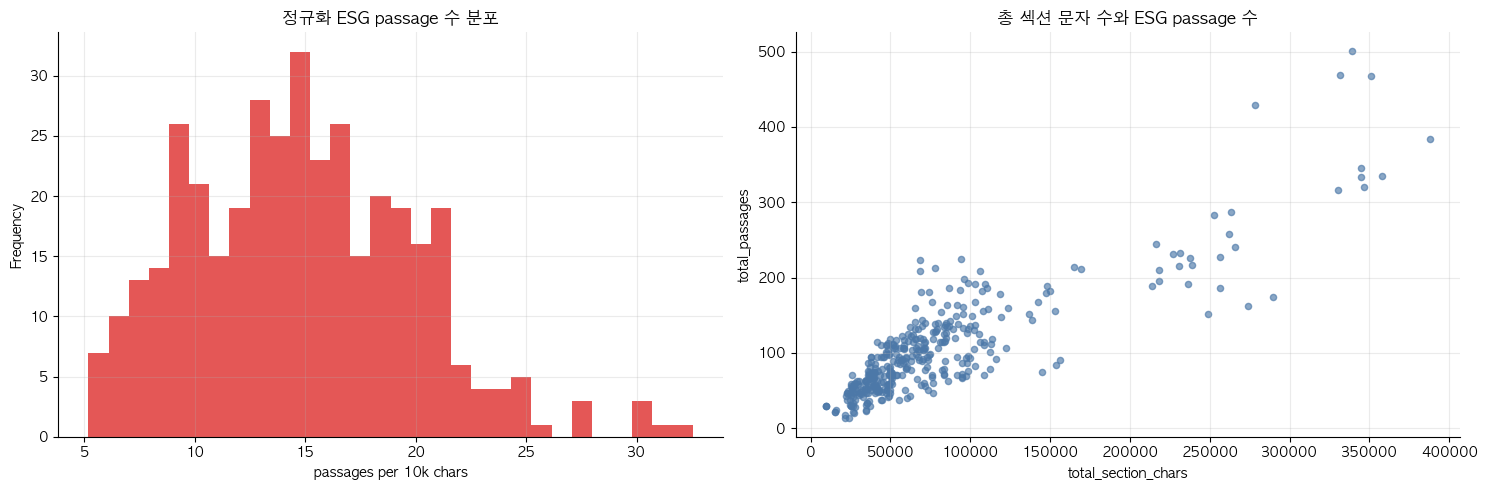

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
panel['passages_per_10k_chars'].plot(kind='hist', bins=30, ax=axes[0], color='#E45756', title='정규화 ESG passage 수 분포')
panel.plot.scatter(x='total_section_chars', y='total_passages', ax=axes[1], alpha=0.65, color='#4C78A8', title='총 섹션 문자 수와 ESG passage 수')
axes[0].set_xlabel('passages per 10k chars')
plt.tight_layout()
plt.show()


## 5. Passage 양과 ESG 등급의 관계

단순 passage 수는 기업 규모나 공시 장황함을 반영할 수 있으므로, `passages_per_10k_chars`를 함께 봅니다.


,feature,grade,n,spearman_rho,spearman_p,pearson_r,pearson_p
1,total_passages,e_grade_num,376.0000,0.6983,0.0000,0.5465,0.0000
17,g_passages,e_grade_num,376.0000,0.6346,0.0000,0.5885,0.0000
13,s_passages,e_grade_num,376.0000,0.6340,0.0000,0.4753,0.0000
37,unique_terms,e_grade_num,376.0000,0.6259,0.0000,0.6081,0.0000
9,e_passages,e_grade_num,376.0000,0.5065,0.0000,0.2740,0.0000
21,e_share,e_grade_num,376.0000,0.3679,0.0000,0.2936,0.0000
33,avg_passage_length,e_grade_num,376.0000,0.3162,0.0000,0.3152,0.0000
25,s_share,e_grade_num,376.0000,0.2811,0.0000,0.2362,0.0000
5,passages_per_10k_chars,e_grade_num,376.0000,0.0460,0.3735,0.0504,0.3301
29,g_share,e_grade_num,376.0000,-0.4309,0.0000,-0.3936,0.0000


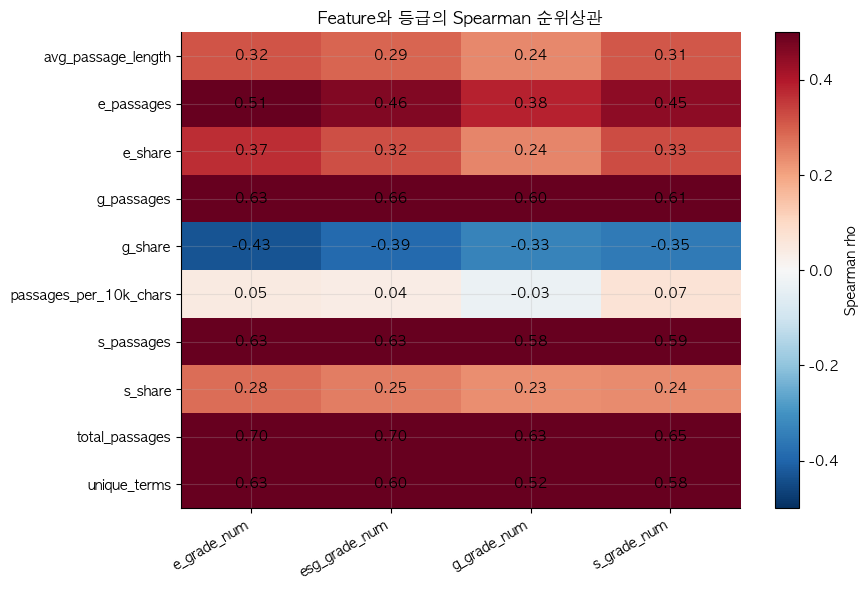

In [13]:
def corr_pair(x, y):
    data = pd.DataFrame({'x': x, 'y': y}).dropna()
    if len(data) < 3:
        return pd.Series({'n': len(data), 'spearman_rho': np.nan, 'spearman_p': np.nan, 'pearson_r': np.nan, 'pearson_p': np.nan})
    if SCIPY_AVAILABLE:
        sp = stats.spearmanr(data['x'], data['y'])
        pe = stats.pearsonr(data['x'], data['y'])
        return pd.Series({'n': len(data), 'spearman_rho': sp.statistic, 'spearman_p': sp.pvalue, 'pearson_r': pe.statistic, 'pearson_p': pe.pvalue})
    return pd.Series({'n': len(data), 'spearman_rho': data['x'].corr(data['y'], method='spearman'), 'spearman_p': np.nan, 'pearson_r': data['x'].corr(data['y']), 'pearson_p': np.nan})

features_for_corr = ['total_passages', 'passages_per_10k_chars', 'e_passages', 's_passages', 'g_passages', 'e_share', 's_share', 'g_share', 'avg_passage_length', 'unique_terms']
grade_targets = ['esg_grade_num', 'e_grade_num', 's_grade_num', 'g_grade_num']

corr_rows = []
for feature in features_for_corr:
    for target in grade_targets:
        row = corr_pair(panel[feature], panel[target])
        row['feature'] = feature
        row['grade'] = target
        corr_rows.append(row)

corr_table = pd.DataFrame(corr_rows)[['feature', 'grade', 'n', 'spearman_rho', 'spearman_p', 'pearson_r', 'pearson_p']]
display(corr_table.sort_values(['grade', 'spearman_rho'], ascending=[True, False]))

heatmap_data = corr_table.pivot(index='feature', columns='grade', values='spearman_rho')
fig, ax = plt.subplots(figsize=(9, 6))
im = ax.imshow(heatmap_data.values, aspect='auto', cmap='RdBu_r', vmin=-0.5, vmax=0.5)
ax.set_xticks(range(len(heatmap_data.columns)))
ax.set_xticklabels(heatmap_data.columns, rotation=30, ha='right')
ax.set_yticks(range(len(heatmap_data.index)))
ax.set_yticklabels(heatmap_data.index)
for i in range(heatmap_data.shape[0]):
    for j in range(heatmap_data.shape[1]):
        value = heatmap_data.iloc[i, j]
        ax.text(j, i, f'{value:.2f}', ha='center', va='center', color='black')
ax.set_title('Feature와 등급의 Spearman 순위상관')
fig.colorbar(im, ax=ax, label='Spearman rho')
plt.tight_layout()
plt.show()


,firm_years,total_passages_mean,total_passages_median,passages_per_10k_mean,seed_ready_docs
esg_grade,,,,,
D,63.0000,48.9365,48.0000,14.9587,63.0000
C,52.0000,61.0192,52.5000,13.3493,52.0000
B,36.0000,86.5278,89.0000,16.2211,36.0000
B+,73.0000,104.1918,90.0000,14.7586,73.0000
A,123.0000,137.3333,120.0000,14.9665,123.0000
A+,29.0000,188.0345,137.0000,15.2401,29.0000


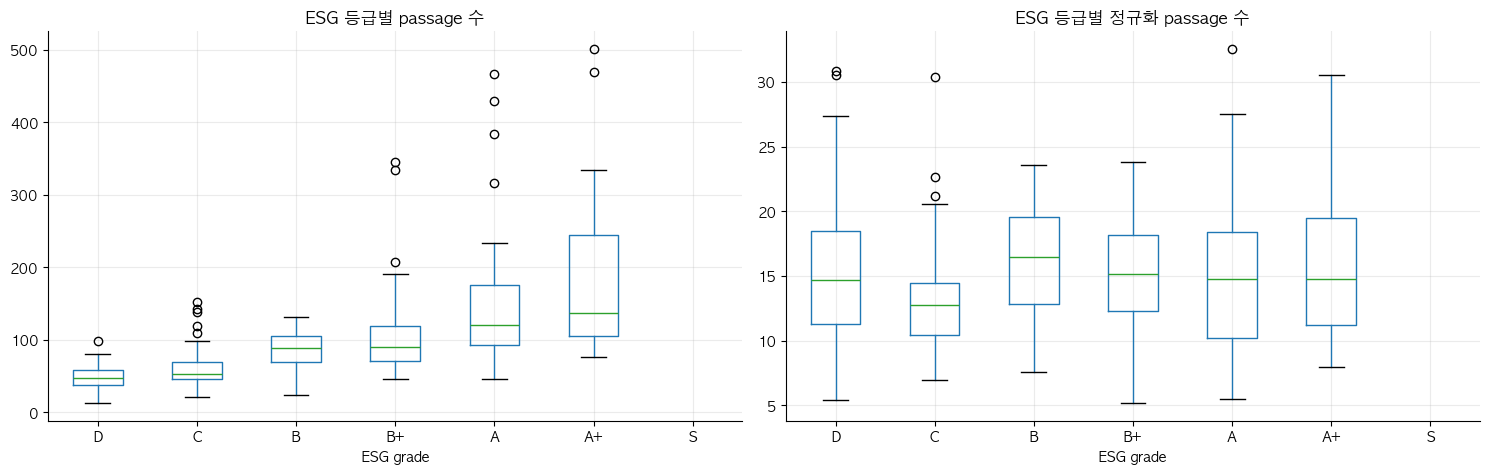

In [14]:
grade_summary = panel.groupby('esg_grade').agg(
    firm_years=('stock_code', 'size'),
    total_passages_mean=('total_passages', 'mean'),
    total_passages_median=('total_passages', 'median'),
    passages_per_10k_mean=('passages_per_10k_chars', 'mean'),
    seed_ready_docs=('document_text', 'size'),
).reindex(GRADE_ORDER).dropna(how='all')
display(grade_summary)

plot_df = panel.copy()
plot_df['esg_grade'] = pd.Categorical(plot_df['esg_grade'], categories=GRADE_ORDER, ordered=True)
plot_df = plot_df.sort_values('esg_grade')

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
plot_df.boxplot(column='total_passages', by='esg_grade', ax=axes[0])
plot_df.boxplot(column='passages_per_10k_chars', by='esg_grade', ax=axes[1])
axes[0].set_title('ESG 등급별 passage 수')
axes[1].set_title('ESG 등급별 정규화 passage 수')
for ax in axes:
    ax.set_xlabel('ESG grade')
plt.suptitle('')
plt.tight_layout()
plt.show()


## 6. Seed dictionary 기반 TF-IDF feature

기업-연도별 ESG passage를 하나의 문서로 묶고, seed dictionary의 패턴에 등장하는 단어를 기준으로 TF-IDF 점수를 합산합니다. 이 feature는 단순 문장 수보다 특정 ESG 어휘가 해당 문서에서 얼마나 두드러지는지 측정합니다.


In [15]:
def split_pattern_terms(pattern):
    terms = []
    for raw in str(pattern).split('|'):
        term = raw.strip()
        if term:
            terms.append(term)
    return terms

seed_terms = (
    seed_dict.assign(term_list=seed_dict['pattern'].map(split_pattern_terms))
    .explode('term_list')
    .rename(columns={'term_list': 'term'})
)
seed_terms['term'] = seed_terms['term'].astype(str).str.strip()
seed_terms = seed_terms[seed_terms['term'].ne('')]
seed_terms_by_dim = {dim: sorted(seed_terms.loc[seed_terms['dimension'].eq(dim), 'term'].unique()) for dim in ['E', 'S', 'G']}
all_seed_terms = sorted(seed_terms['term'].unique())

print('seed terms by dimension')
for dim, terms in seed_terms_by_dim.items():
    print(dim, len(terms), terms)

# token_pattern은 한글/영문/숫자 토큰을 2글자 이상 잡는다. seed 용어 중 띄어쓰기 표현은 개별 토큰 점수로 반영된다.
vectorizer = TfidfVectorizer(token_pattern=r'(?u)\b[\w가-힣A-Za-z]{2,}\b', lowercase=True, min_df=1)
tfidf = vectorizer.fit_transform(panel['document_text'].fillna(''))
vocab = vectorizer.get_feature_names_out()
vocab_index = {term: i for i, term in enumerate(vocab)}

score_df = pd.DataFrame(index=panel.index)
for dim, terms in seed_terms_by_dim.items():
    matched_vocab_terms = [term.lower() for term in terms if term.lower() in vocab_index]
    matched_indices = [vocab_index[term] for term in matched_vocab_terms]
    score_col = f'seed_{dim.lower()}_tfidf'
    score_df[score_col] = np.asarray(tfidf[:, matched_indices].sum(axis=1)).ravel() if matched_indices else 0.0
    print(dim, 'matched vocab terms:', len(matched_vocab_terms), matched_vocab_terms)

panel = pd.concat([panel, score_df], axis=1)
panel['seed_total_tfidf'] = panel[['seed_e_tfidf', 'seed_s_tfidf', 'seed_g_tfidf']].sum(axis=1)

display(panel[['company_name', 'stock_code_str', 'esg_year', 'seed_total_tfidf', 'seed_e_tfidf', 'seed_s_tfidf', 'seed_g_tfidf']].sort_values('seed_total_tfidf', ascending=False).head(10))


seed terms by dimension
E 18 ['GHG', 'net zero', 'net-zero', 'renewable energy', '넷제로', '물관리', '수질', '에너지', '온실가스', '자원순환', '재생에너지', '재활용', '전력', '전력사용량', '탄소', '탄소중립', '폐기물', '폐수']
S 18 ['community', 'supply chain', '공급망', '교육', '교육훈련', '근로자', '노동', '노사', '산업재해', '안전', '인권', '임직원', '재해율', '중대재해', '지역사회', '직원', '협력사', '훈련']
G 17 ['anti-corruption', 'compliance', 'ethic', 'ethical', 'independence', 'voting rights', '감사위원회', '독립성', '반부패', '부패방지', '사외이사', '윤리', '의결권', '이사회', '주주', '준법', '컴플라이언스']
E matched vocab terms: 14 ['넷제로', '물관리', '수질', '에너지', '온실가스', '자원순환', '재생에너지', '재활용', '전력', '전력사용량', '탄소', '탄소중립', '폐기물', '폐수']
S matched vocab terms: 17 ['community', '공급망', '교육', '교육훈련', '근로자', '노동', '노사', '산업재해', '안전', '인권', '임직원', '재해율', '중대재해', '지역사회', '직원', '협력사', '훈련']
G matched vocab terms: 13 ['compliance', 'ethical', '감사위원회', '독립성', '반부패', '부패방지', '사외이사', '윤리', '의결권', '이사회', '주주', '준법', '컴플라이언스']


,company_name,stock_code_str,esg_year,seed_total_tfidf,seed_e_tfidf,seed_s_tfidf,seed_g_tfidf
195,대한전선,001440,2025,1.1883,0.1023,0.4380,0.6481
136,CJ,001040,2024,1.0186,0.3291,0.2224,0.4671
137,CJ,001040,2025,0.9318,0.2400,0.2238,0.4679
361,CJ제일제당,097950,2023,0.9160,0.4508,0.0990,0.3661
261,깨끗한나라,004540,2025,0.8700,0.5409,0.1218,0.2072
362,CJ제일제당,097950,2024,0.8341,0.3995,0.1004,0.3341
304,롯데케미칼,011170,2023,0.8330,0.3419,0.0930,0.3981
135,CJ,001040,2023,0.8137,0.3370,0.1762,0.3006
276,POSCO홀딩스,005490,2025,0.7945,0.3883,0.2780,0.1281
114,한화,000880,2023,0.7779,0.4931,0.1571,0.1277


,feature,grade,n,spearman_rho,spearman_p,pearson_r,pearson_p
1,seed_total_tfidf,e_grade_num,376.0000,0.5355,0.0000,0.5263,0.0000
5,seed_e_tfidf,e_grade_num,376.0000,0.4346,0.0000,0.3245,0.0000
9,seed_s_tfidf,e_grade_num,376.0000,0.4047,0.0000,0.3625,0.0000
13,seed_g_tfidf,e_grade_num,376.0000,0.3085,0.0000,0.3450,0.0000
0,seed_total_tfidf,esg_grade_num,376.0000,0.6195,0.0000,0.5837,0.0000
12,seed_g_tfidf,esg_grade_num,376.0000,0.4291,0.0000,0.4465,0.0000
8,seed_s_tfidf,esg_grade_num,376.0000,0.4278,0.0000,0.3899,0.0000
4,seed_e_tfidf,esg_grade_num,376.0000,0.3812,0.0000,0.3065,0.0000
3,seed_total_tfidf,g_grade_num,376.0000,0.5679,0.0000,0.5246,0.0000
15,seed_g_tfidf,g_grade_num,376.0000,0.4247,0.0000,0.4317,0.0000


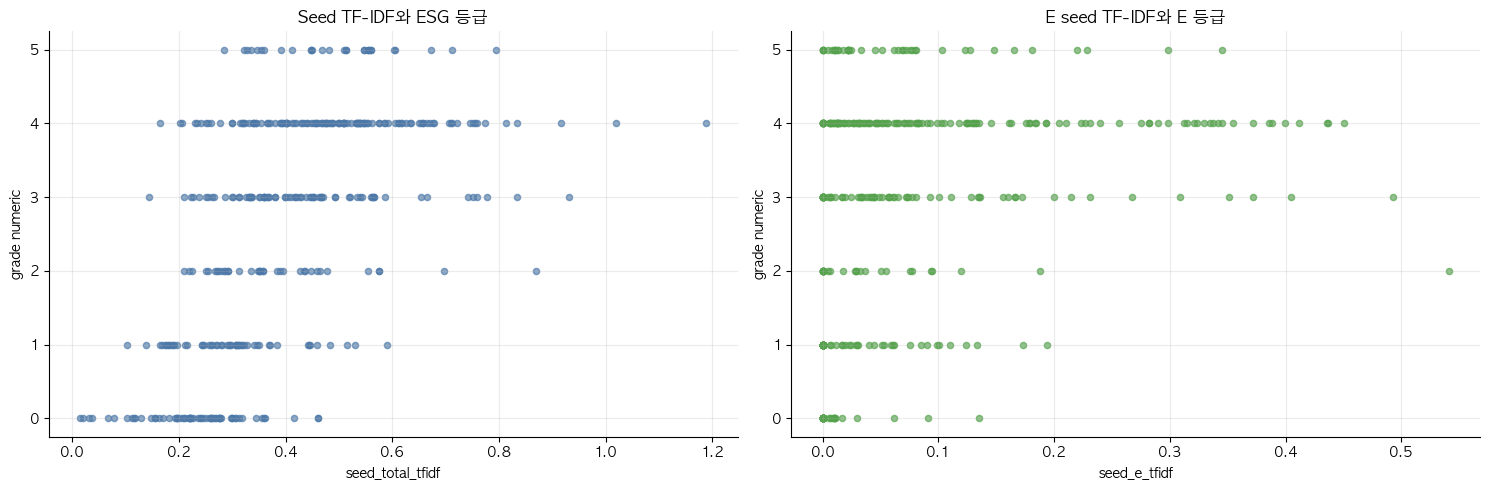

In [16]:
tfidf_features = ['seed_total_tfidf', 'seed_e_tfidf', 'seed_s_tfidf', 'seed_g_tfidf']
tfidf_corr = []
for feature in tfidf_features:
    for target in grade_targets:
        row = corr_pair(panel[feature], panel[target])
        row['feature'] = feature
        row['grade'] = target
        tfidf_corr.append(row)

tfidf_corr_table = pd.DataFrame(tfidf_corr)[['feature', 'grade', 'n', 'spearman_rho', 'spearman_p', 'pearson_r', 'pearson_p']]
display(tfidf_corr_table.sort_values(['grade', 'spearman_rho'], ascending=[True, False]))

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
panel.plot.scatter(x='seed_total_tfidf', y='esg_grade_num', ax=axes[0], alpha=0.65, color='#4C78A8', title='Seed TF-IDF와 ESG 등급')
panel.plot.scatter(x='seed_e_tfidf', y='e_grade_num', ax=axes[1], alpha=0.65, color='#54A24B', title='E seed TF-IDF와 E 등급')
for ax in axes:
    ax.set_ylabel('grade numeric')
plt.tight_layout()
plt.show()


,feature,high_n,low_n,high_mean,low_mean,mean_diff,mannwhitney_p,ttest_p
0,seed_total_tfidf,152,224,0.4997,0.3366,0.1632,0.0000,0.0000
1,total_passages,152,224,147.0066,75.7902,71.2164,0.0000,0.0000
2,passages_per_10k_chars,152,224,15.0187,14.7228,0.2960,0.7311,0.5871
3,unique_terms,152,224,23.0395,16.6295,6.4100,0.0000,0.0000


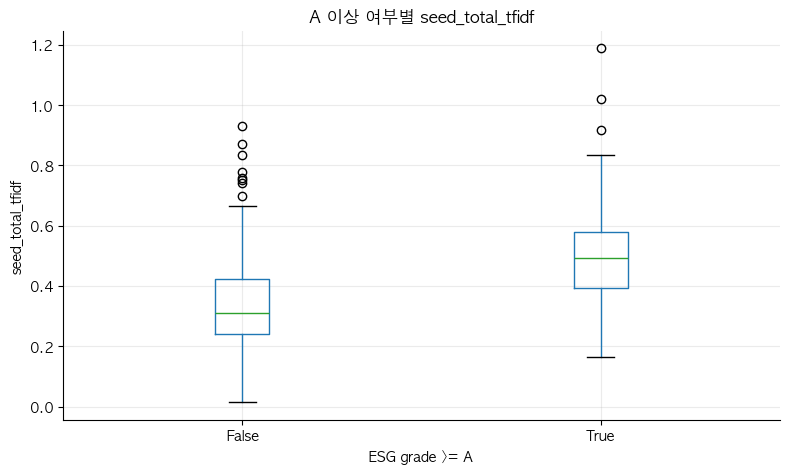

In [17]:
panel['high_grade_a_or_above'] = panel['esg_grade_num'].ge(GRADE_MAP['A'])

def group_diff_test(feature, group_col='high_grade_a_or_above'):
    high = panel.loc[panel[group_col], feature].dropna()
    low = panel.loc[~panel[group_col], feature].dropna()
    result = {
        'feature': feature,
        'high_n': len(high),
        'low_n': len(low),
        'high_mean': high.mean(),
        'low_mean': low.mean(),
        'mean_diff': high.mean() - low.mean(),
        'mannwhitney_p': np.nan,
        'ttest_p': np.nan,
    }
    if SCIPY_AVAILABLE and len(high) > 1 and len(low) > 1:
        result['mannwhitney_p'] = stats.mannwhitneyu(high, low, alternative='two-sided').pvalue
        result['ttest_p'] = stats.ttest_ind(high, low, equal_var=False, nan_policy='omit').pvalue
    return result

group_tests = pd.DataFrame([group_diff_test(f) for f in ['seed_total_tfidf', 'total_passages', 'passages_per_10k_chars', 'unique_terms']])
display(group_tests)

fig, ax = plt.subplots(figsize=(8, 5))
panel.boxplot(column='seed_total_tfidf', by='high_grade_a_or_above', ax=ax)
ax.set_title('A 이상 여부별 seed_total_tfidf')
ax.set_xlabel('ESG grade >= A')
ax.set_ylabel('seed_total_tfidf')
plt.suptitle('')
plt.tight_layout()
plt.show()


## 7. Baseline OLS 회귀

ESG 등급은 서열변수이므로 ordered logit이 더 자연스러울 수 있지만, 본 노트북은 추가 의존성을 피하고 해석이 쉬운 baseline OLS를 사용합니다. 계수는 인과효과가 아니라 조건부 연관성으로만 해석합니다.


In [18]:
def fit_ols_sklearn(df, y_col, x_cols):
    model_df = df[[y_col] + x_cols].replace([np.inf, -np.inf], np.nan).dropna()
    X = model_df[x_cols]
    y = model_df[y_col]
    model = LinearRegression()
    model.fit(X, y)
    pred = model.predict(X)
    return pd.Series({
        'n': len(model_df),
        'r2': r2_score(y, pred),
        'intercept': model.intercept_,
        **{f'beta_{col}': coef for col, coef in zip(x_cols, model.coef_)},
    })

ols_specs = {
    'M1_seed_only': ['seed_total_tfidf'],
    'M2_seed_plus_passage_count': ['seed_total_tfidf', 'total_passages'],
    'M3_seed_plus_verbosity': ['seed_total_tfidf', 'total_section_chars', 'passages_per_10k_chars'],
    'M4_dimension_seed': ['seed_e_tfidf', 'seed_s_tfidf', 'seed_g_tfidf', 'total_section_chars'],
}

ols_results = pd.DataFrame([fit_ols_sklearn(panel, 'esg_grade_num', x_cols).rename(spec) for spec, x_cols in ols_specs.items()])
display(ols_results)


,n,r2,intercept,beta_seed_total_tfidf,beta_total_passages,beta_total_section_chars,beta_passages_per_10k_chars,beta_seed_e_tfidf,beta_seed_s_tfidf,beta_seed_g_tfidf
M1_seed_only,376.0000,0.3407,0.4159,5.4418,NaN,NaN,NaN,NaN,NaN,NaN
M2_seed_plus_passage_count,376.0000,0.4312,0.2892,3.5953,0.0083,NaN,NaN,NaN,NaN,NaN
M3_seed_plus_verbosity,376.0000,0.4174,-0.1150,4.0212,NaN,0.0000,0.0299,NaN,NaN,NaN
M4_dimension_seed,376.0000,0.4436,-0.1358,NaN,NaN,0.0000,NaN,2.5329,3.2793,6.5282


## 8. 알파 분석: section-specific feature

같은 ESG passage라도 사업의 내용(II), 이사회/임원 및 직원(IV), 주주 관련 사항(VI) 중 어디에 등장하는지에 따라 의미가 다를 수 있습니다. 여기서는 섹션별 passage 비중과 등급의 Spearman 관계를 확인합니다.


,feature,grade,n,spearman_rho,spearman_p,pearson_r,pearson_p
2,section_VI_passages,esg_grade_num,376.0000,0.6539,0.0000,0.5864,0.0000
0,section_II_passages,esg_grade_num,376.0000,0.5549,0.0000,0.3839,0.0000
1,section_IV_passages,esg_grade_num,376.0000,0.4900,0.0000,0.2623,0.0000
3,section_II_share,esg_grade_num,376.0000,0.2564,0.0000,0.2246,0.0000
4,section_IV_share,esg_grade_num,376.0000,0.2285,0.0000,0.2373,0.0000
5,section_VI_share,esg_grade_num,376.0000,-0.3141,0.0000,-0.2854,0.0000


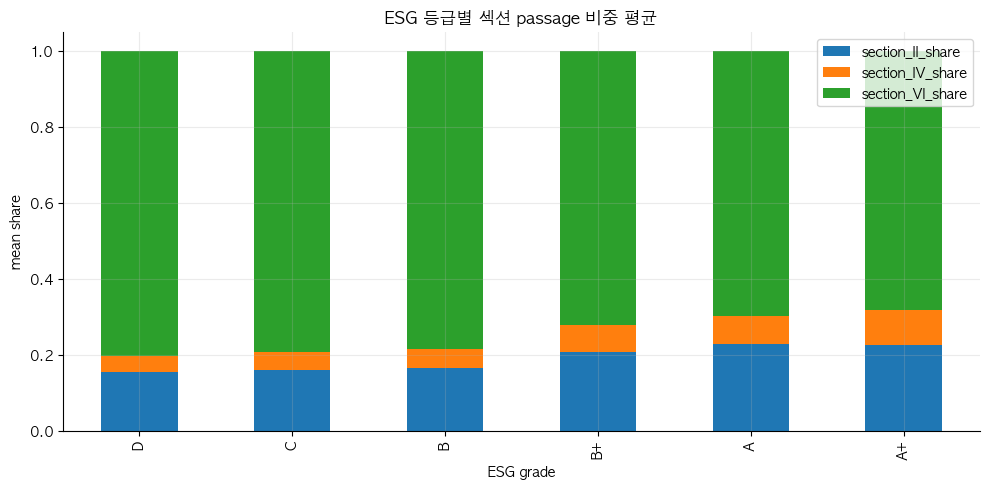

In [19]:
section_features = ['section_II_passages', 'section_IV_passages', 'section_VI_passages', 'section_II_share', 'section_IV_share', 'section_VI_share']
section_corr_rows = []
for feature in section_features:
    row = corr_pair(panel[feature], panel['esg_grade_num'])
    row['feature'] = feature
    row['grade'] = 'esg_grade_num'
    section_corr_rows.append(row)
section_corr = pd.DataFrame(section_corr_rows)[['feature', 'grade', 'n', 'spearman_rho', 'spearman_p', 'pearson_r', 'pearson_p']]
display(section_corr.sort_values('spearman_rho', ascending=False))

section_share_mean = panel.groupby('esg_grade')[['section_II_share', 'section_IV_share', 'section_VI_share']].mean().reindex(GRADE_ORDER).dropna(how='all')
section_share_mean.plot(kind='bar', stacked=True, figsize=(10, 5), title='ESG 등급별 섹션 passage 비중 평균')
plt.xlabel('ESG grade')
plt.ylabel('mean share')
plt.tight_layout()
plt.show()


## 9. Feature 해석 확인: 상위/하위 문장 예시

TF-IDF score가 높은 기업-연도와 낮은 기업-연도의 실제 passage를 읽어 feature가 의도한 ESG 표현을 포착하는지 점검합니다.


In [20]:
def show_example_passages(panel_df, passages_df, sort_col, top=True, n_docs=3, n_passages=3):
    selected = panel_df.sort_values(sort_col, ascending=not top).head(n_docs)
    direction = '상위' if top else '하위'
    print(f'[{sort_col} {direction} {n_docs}개 기업-연도]')
    for _, row in selected.iterrows():
        mask = passages_df['stock_code'].eq(row['stock_code']) & passages_df['esg_year'].eq(row['esg_year'])
        sample = passages_df.loc[mask, ['section', 'dimension', 'matched_terms', 'passage']].head(n_passages)
        print('\n', row['company_name'], row['stock_code_str'], int(row['esg_year']), row['esg_grade'], f'{sort_col}={row[sort_col]:.4f}')
        display(sample)

show_example_passages(panel, passages_eda, 'seed_total_tfidf', top=True)
show_example_passages(panel, passages_eda, 'seed_total_tfidf', top=False)


[seed_total_tfidf 상위 3개 기업-연도]

 대한전선 001440 2025 A seed_total_tfidf=1.1883


,section,dimension,matched_terms,passage
22841,II,E,전력,"당사는 전선제조 및 판매 사업 등을 영위할 목적으로 1955년 2월 21일에 설립되었으며, 1968년 12월 27일 한국거래소 유가증권시장에 주식을 상장하였습니다.대한전선 주식회사 및 종속회사는 전선부문 단일..."
22842,II,E,전력,"전선부문 \n전력 및 절연선 \n발전소에서 발전된 전력을 소비지의 변전소에 보내는 송전선과 전기인입구까지 인입된 전력을 사용장소까지 인도해주는 배전선, 그리고 최종 사용장소의 실내외에 전력을 보급하는 배선 등..."
22843,II,E,에너지|전력,"나선 및 권선 \n통신선, 전력선, 권선 등의 도체용 및 전기기기의 내부에 코일상태로 감겨져서 기계적 에너지를 전기적 에너지로 변환시키거나 전기적 에너지를 기계적 에너지로 변환시키는데 사용"



 CJ 001040 2024 A seed_total_tfidf=1.0186


,section,dimension,matched_terms,passage
1971,II,S,안전,"CJ프레시웨이의 사업영역은 크게 식자재유통사업 및 푸드서비스사업, 제조/서비스업으로 구성되어 있고, 업계 최고 수준의 위생/안전시스템, 물류/IT 인프라를 보유하고 있습니다"
1972,II,S,교육|교육훈련,"식자재유통 사업의 마켓리더로서 상품공급뿐만 아니라 메뉴, 조리, 서비스, 위생 교육 및 컨설팅 등 다양한 부가서비스를 지원하여 식당 운영의 토탈 솔루션을 제공하는 기업으로 자리매김하고 있습니다"
1973,II,S,안전,"단체급식업계 최초로 ISO22000 인증 및 병원 HACCP인증을 획득하고 QSC(Quality, Service, Cleanliness)에 대한 철저한 관리를 실시함으로써 안전하고 믿을 수 있는 급식 서비스를..."



 CJ 001040 2025 B+ seed_total_tfidf=0.9318


...

,section,dimension,matched_terms,passage
36838,II,E,에너지,EV기종인 E-LUTION 기종은 LG에너지솔루션[사내독립기업 쿠루(KooRoo)]의 배터리 교환형 충전 스테이션과 연계하여 ‘24년 6월3일 울산현대중공업내에 임직원용으로33대 납품을 시작으로 지속적으로 판...
36839,II,S,임직원,EV기종인 E-LUTION 기종은 LG에너지솔루션[사내독립기업 쿠루(KooRoo)]의 배터리 교환형 충전 스테이션과 연계하여 ‘24년 6월3일 울산현대중공업내에 임직원용으로33대 납품을 시작으로 지속적으로 판...
36840,II,G,이사회,"연결회사의 재무부문은 이사회에서 승인된 위험관리 정책 및 절차에 따라 연결회사의 영업과 관련한 금융위험을 감시하고 관리하는 역할을 하고 있으며, 금융위험의 성격과 노출정도를 분석한 주기적인 내부위험보고서를 위..."



 KR모터스 000040 2024 D seed_total_tfidf=0.0200


,section,dimension,matched_terms,passage
36825,II,G,이사회,"연결회사의 재무부문은 이사회에서 승인된 위험관리 정책 및 절차에 따라 연결회사의 영업과 관련한 금융위험을 감시하고 관리하는 역할을 하고 있으며, 금융위험의 성격과 노출정도를 분석한 주기적인 내부위험보고서를 위..."
36826,II,E,에너지,- 2023.05.26 태국 PAP 스마트에너지사와 전기기이륜차 공급계약 체결- 2023.06.20 이륜차 종합 솔루션 기업 온어스와 전략적 제휴 MOU 협약 체결- 2023.07.04 대만 SYM사와 국내 ...
36827,II,E,전력,"연구개발 설비 \n \n전기차 인증용 장비 시설 보강 \n \n-1충전주행거리의 정확한 측정을 위한 검출 장비 보강, -직류/교류 소비(충전)전력량 측정의 검교정 가능 형태 \n22년11월 ~ 23년03월"



 한국주철관공업 000970 2024 D seed_total_tfidf=0.0327


,section,dimension,matched_terms,passage
37738,II,S,안전,"화장품 산업은다른 산업 분야와달리 신제품 개발과 외형적 성장 추구 이외에 인간의 건강과 아름다움에 관련되는 욕구를 충족시켜주는 특수한 효익을 가지고 있으므로 생산, 디자인, 유통, 판매, 광고 및 소비에 이르..."
37739,II,G,주주,라. 자본관리자본관리의 주 목적은 당사의 영업활동을 유지하고 주주가치를 극대화하기 위하여 높은 신용등급과 건전한 자본비율을 유지하기 위한 것입니다
37740,II,G,주주,당사의 자본관리는 건전한 자본구조의 유지를 통한 주주이익 극대화를 목적으로 하고 있습니다


## 10. 정리 및 보고서에 남길 해석 포인트

- 표본은 `company_master.csv` 기준 381개 기업-연도이며, 분석 corpus는 passage 추출에 성공한 376개 기업-연도입니다.
- 실패 행은 텍스트 점수 0으로 대체하지 않고 lineage 표에서 별도로 설명합니다.
- Spearman 순위상관은 ESG 등급이 서열변수라는 점 때문에 Pearson보다 우선 해석합니다.
- passage 수와 TF-IDF score는 실제 ESG 성과가 아니라 사업보고서 공시 언어의 양과 어휘적 두드러짐을 측정합니다.
- OLS 결과는 baseline 연관성으로만 읽고, cheap-talk 가능성 때문에 공시 분량 통제 변수를 함께 봅니다.
